# Step 12 — Supervised comparison: can next month's regime be predicted, not just described?

The rubric asked for supervised models, cross-validation and grid search; this notebook supplies them as an
honest model comparison rather than a new production layer. Logistic regression and a random forest predict
whether next month is an official STRESS month from the detector's three features, with temporal
cross-validation (`TimeSeriesSplit`, a one-month gap that enforces the project's label-lag rule), small
pre-declared grids, recall on STRESS as the primary metric and persistence ("next month = this month") as the
baseline to beat. All of that is fixed in markdown before any result appears. Verdict: **neither model beats
persistence** out-of-fold — two more stress months caught, bought with 17–22 extra false alarms — and the
coefficients show why: the models learn the detector's own definition of stress, one month early and
therefore more often wrong. The frozen configuration is unchanged.

<details>
<summary><b>Specification — the prompt for this step, verbatim (click to expand)</b></summary>

# Step 12 — Specification

> Full prompt for this step, reproduced verbatim (capstone_project_rules.md code-style rule: each notebook opens
> with its own spec so it is self-contained). Sections B–C of the same prompt (README replacement, repo
> housekeeping) are not notebook work and are omitted here.

```
Context: final capstone submission (Berkeley ML/AI certificate), repo Capstone001.
Grading rubric: 5 criteria x 10 pts (Organization / Code Quality / Visualizations /
Modeling / Findings). The repo is complete through notebook 11; this session closes
the remaining rubric gaps. Read "capstone_project_rules.md" (project rules) first.
Data constraint, as always: run everything against the frozen data/ snapshot
(REFRESH_DATA stays False); never re-download.

## A. New notebook: 12_supervised.ipynb — supervised model comparison

Purpose: the rubric's Modeling criterion requires "multiple regression or
classification models", "cross-validation of models" and "grid search
hyperparameters" — none currently in the repo (K-means and HMM are unsupervised;
hyperparameters were deliberately pre-declared, not searched). This notebook
closes all three honestly, as a model comparison under project rule 6
("simple beats sophisticated until proven otherwise").

A1. Task definition (markdown first, before any code): binary classification —
    predict whether month T+1 is an official STRESS month, using only features
    available at month-end T. Labels come from the production K-means detector's
    official regime series in outputs/ (the post-hysteresis labels). State in
    markdown why this is the right supervised framing: the unsupervised detector
    DESCRIBES the present; these models attempt to PREDICT one step ahead, and
    whether prediction beats description is the question.
A2. Label lag (project rule 5): the label for month T is only known after the
    hysteresis confirms; when training at date T, exclude the most recent
    unconfirmed months from the training set. Implement explicitly and comment
    WHY (this is the anti-leakage rule the project declared but never exercised).
A3. Features: the detector's three (realized vol, trailing return, cross-asset
    correlation) at month-end, point-in-time, z-scored with expanding mean/std.
    For the LOGISTIC model only, add the interaction term vol x correlation
    (markdown: linear models need interactions to curve the boundary; distance-
    based clustering does not — that's why the K-means detector never got them).
A4. Two models: LogisticRegression and RandomForestClassifier (sklearn).
A5. Cross-validation: sklearn TimeSeriesSplit (5 splits). Markdown must name it
    explicitly as temporal cross-validation and explain why standard k-fold
    shuffling is forbidden here (it would train on the future).
A6. Grid search: GridSearchCV with the TimeSeriesSplit as cv. Small, pre-declared
    grids — logistic: C in {0.01, 0.1, 1, 10}, penalty l2; RF: max_depth in
    {2, 3, 5}, n_estimators in {100, 300}, min_samples_leaf in {5, 10}. Scoring:
    recall on the STRESS class (see A7). Declare the grids in markdown BEFORE the
    search cell; no grid changes after seeing results.
A7. Evaluation metric, declared with rationale BEFORE results: primary = recall
    on STRESS (a missed stress month costs far more than a false alarm — the
    project's asymmetry-of-harms principle turned into a metric choice);
    secondary = precision on STRESS and balanced accuracy. Report a confusion
    matrix per model on the held-out folds. Interpret: what does each false
    negative / false positive cost in portfolio terms?
A8. Honest baselines to beat, same table: (a) persistence — predict for T+1
    whatever the official regime was at T; (b) always-CALM. If the tuned models
    don't beat persistence out-of-fold, SAY SO — under rule 6 that is the
    expected and acceptable outcome, documented like every other negative
    finding. Do NOT promote any supervised model into the production pipeline;
    final markdown states the frozen configuration is unchanged.
A9. Class imbalance: STRESS is ~14% of months. Use class_weight='balanced' for
    both models and note it in markdown.
A10. Visuals: confusion matrices (matplotlib subplots, titled, labeled) + ONE
     Plotly chart: predicted stress probability over time (logistic), with
     official stress months shaded — hover shows date and probability.
A11. Standard format: first cell = this spec verbatim ("# Step 12 —
     Specification"); headings; WHY-comments on non-obvious code; no long
     raw outputs.
```

</details>

## 1 — Task definition (read before any code)

**Binary classification, one step ahead.** For every month-end **T** we ask: *will month **T+1** be an
official STRESS month?* The prediction may use **only information available at month-end T**.

- **Labels** come from the production K-means detector's **official** regime series in
  `outputs/regime_v1.parquet`, column `official_v2` — the post-hysteresis labels (asymmetric rule: enter
  STRESS on one raw signal, leave it only after two consecutive non-STRESS signals; 5-year rolling training
  window — the series Steps 7–11 read). `y_T = 1` if `official_v2[T+1] == STRESS`, else `0`. The last month
  of the series (2026-07) has no T+1 and is dropped, leaving **162 samples**.
- **Why this is the right supervised framing.** The unsupervised detector **describes the present**: at
  month-end T it says which regime the market *is in*, and the pipeline then sets next month's exposure from
  that description. A supervised model attempts something stronger — to **predict** the regime one month
  ahead. Whether *prediction beats description* is the question, and it has a built-in yardstick: the
  **persistence** baseline ("next month = this month") is exactly what the production pipeline already does
  implicitly. If a tuned classifier cannot beat persistence on held-out months, supervised learning adds
  nothing the detector does not already give — under rule 6 that is an acceptable answer, not a failure.
- **Class imbalance (A9):** STRESS is 23 of 162 target months (14.2%). Both models use
  `class_weight='balanced'`, so a missed STRESS month weighs about six times a missed non-STRESS month during
  fitting; without it a model could reach 86% accuracy by never predicting STRESS.
- **Nothing here touches production.** Whatever the result, the frozen configuration (V-AB, K-means
  detector) is unchanged; this notebook is a model comparison for the record.

## 2 — Label lag (project rule 5) and temporal cross-validation, declared before any model is fitted

**Label lag.** Sample T's label is the official regime of month **T+1**. It does not exist at T; it is
realized at month-end T+1, when the hysteresis has processed that month's raw K-means signal (the
asymmetric rule looks at the raw labels of T+1 and T, so once written the official label is never revised —
the lag is the prediction horizon itself, one month). Rule 5 says: *when training at date T, samples in
(T−H, T] have no label yet — exclude them.* Here H = 1 month. We enforce it mechanically with the `gap`
argument of `TimeSeriesSplit`: in every fold, the training set stops **one sample before** the first test
month, so **no training label is realized at or after the date of the first prediction**. Without the gap,
the last training sample's label would be the official regime of the very month in which the first test
prediction is issued — information that only becomes final at that same month-end. This is the anti-leakage
rule the project declared in its rules file but had not exercised until now.

**Temporal cross-validation (A5).** We use `sklearn.model_selection.TimeSeriesSplit` — folds are
contiguous blocks in time, every training set lies strictly **before** its test block, and training sets
expand fold by fold. **Standard k-fold with shuffling is forbidden here**: it would place 2020 months in the
training set when predicting 2016, i.e. train on the future. Regimes are also persistent (STRESS comes in
runs of 2–5 months), so shuffled folds would leak the *same episode* into train and test and inflate every
score.

**Fold sizing — a design constraint found on the labels alone, before any feature or model was looked at.**
With sklearn's default sizing, `TimeSeriesSplit(n_splits=5)` on 162 samples gives test blocks of 27 months
and a first training window of 2013-01 → 2015-03, which contains **zero** STRESS months — no classifier can be
fitted on a single class. We therefore declare `TimeSeriesSplit(n_splits=5, test_size=24, gap=1)`:
five two-year test blocks (120 held-out months in total), a first training window that reaches mid-2016 and
so includes the first STRESS episode (Jan–Mar 2016), and the one-month gap from the label-lag rule. The code
cell below prints both fold tables as evidence and asserts that every fold has both classes in train and in
test. The scheme is fixed from here on.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import TimeSeriesSplit

REG3 = ["CALM", "NORMAL", "STRESS"]
CWD = Path.cwd(); ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

reg = pd.read_parquet(OUT_DIR / "regime_v1.parquet").set_index("date").sort_index()
months = reg.index                                    # 163 month-ends, 2013-01 -> 2026-07

# Target: y_T = 1 if the OFFICIAL regime of month T+1 is STRESS. The last month has no T+1 -> dropped.
official = reg["official_v2"]                         # production series: asymmetric hysteresis, 5y rolling window
y = (official.shift(-1) == "STRESS").astype(int).iloc[:-1]
y.index.name = "issued_at"                            # the date the prediction is made (month-end T)
target_month = pd.Series(months[1:], index=y.index)   # the month each label refers to (T+1)
persistence = (official == "STRESS").astype(int).iloc[:-1]   # baseline (a): the regime at T, carried to T+1

print(f"samples: {len(y)}  issued {y.index[0].date()} -> {y.index[-1].date()}  "
      f"(targets {target_month.iloc[0].date()} -> {target_month.iloc[-1].date()})")
print(f"STRESS targets: {int(y.sum())}/{len(y)} = {y.mean():.1%}   <- class imbalance (A9)")

samples: 162  issued 2013-01-31 -> 2026-06-30  (targets 2013-02-28 -> 2026-07-31)
STRESS targets: 23/162 = 14.2%   <- class imbalance (A9)


In [2]:
def fold_table(cv, y):
    rows = []
    for k, (tr, te) in enumerate(cv.split(y), 1):
        rows.append({"fold": k, "train_n": len(tr), "train_STRESS": int(y.iloc[tr].sum()),
                     "train_end": y.index[tr[-1]].date(),
                     "test_start": y.index[te[0]].date(), "test_end": y.index[te[-1]].date(),
                     "test_n": len(te), "test_STRESS": int(y.iloc[te].sum())})
    return pd.DataFrame(rows).set_index("fold")

print("sklearn DEFAULT sizing, TimeSeriesSplit(n_splits=5)  [labels only, no model]:")
print(fold_table(TimeSeriesSplit(n_splits=5), y).to_string())
print("\n-> fold 1 would train on ZERO STRESS months: a classifier cannot be fitted on one class.\n")

# DECLARED scheme (markdown above): 5 folds x 24 test months, gap=1 = the label-lag rule (rule 5, H = 1 month).
CV = TimeSeriesSplit(n_splits=5, test_size=24, gap=1)
folds = fold_table(CV, y)
print("DECLARED scheme, TimeSeriesSplit(n_splits=5, test_size=24, gap=1):")
print(folds.to_string())
assert (folds["train_STRESS"] > 0).all() and (folds["test_STRESS"] > 0).all(), "every fold needs both classes"
# WHY the gap matters, in dates: the last training label of each fold is realized one month BEFORE the first
# test prediction is issued (train_end + 1 month < test_start), never at or after it.

sklearn DEFAULT sizing, TimeSeriesSplit(n_splits=5)  [labels only, no model]:
      train_n  train_STRESS   train_end  test_start    test_end  test_n  test_STRESS
fold                                                                                
1          27             0  2015-03-31  2015-04-30  2017-06-30      27            3
2          54             3  2017-06-30  2017-07-31  2019-09-30      27            9
3          81            12  2019-09-30  2019-10-31  2021-12-31      27            4
4         108            16  2021-12-31  2022-01-31  2024-03-31      27            4
5         135            20  2024-03-31  2024-04-30  2026-06-30      27            3

-> fold 1 would train on ZERO STRESS months: a classifier cannot be fitted on one class.

DECLARED scheme, TimeSeriesSplit(n_splits=5, test_size=24, gap=1):
      train_n  train_STRESS   train_end  test_start    test_end  test_n  test_STRESS
fold                                                                                

## 3 — Features (A3)

The detector's own three market-condition features, as of month-end T — the last weekly observation at or
before T, exactly as Step 6 stored them (a gate below asserts equality with the stored values):

| feature | definition (weekly, SPY and the four equity ETFs only) |
|---|---|
| `realized_vol` | trailing 8-week std of SPY weekly returns, annualized |
| `trailing_ret` | trailing 13-week cumulative SPY return |
| `avg_corr` | mean of the 6 pairwise 26-week correlations among SPY, VEA, XLE, XLU |

**Point-in-time standardization.** Each feature is z-scored with the **expanding** mean and std of its own
weekly history up to T — never with full-sample statistics, which would leak the level and dispersion of
future years into early samples. The weekly series starts in 2008, so by the first sample (2013-01) the
scaler already has five years behind it.

**Interaction term, logistic model only.** A logistic regression draws a *linear* boundary in feature space;
"high volatility **and** high correlation" (the signature of a sell-off in which everything falls together)
is not expressible by adding the two effects — it needs the product. So the logistic model gets a fourth
column, `realized_vol × avg_corr` (product of the z-scores). The random forest does not: trees build
interactions by splitting successively. And this is why the K-means detector never had interaction terms:
distance-based clustering groups points by proximity in the raw feature space, where "high vol *and* high
corr" is simply a corner of the space; it has no boundary to curve.

In [3]:
rw = pd.read_parquet(DATA_DIR / "returns_weekly.parquet")
EQ = ["SPY", "VEA", "XLE", "XLU"]
realized_vol = rw["SPY"].rolling(8).std() * np.sqrt(52)
trailing_ret = (1 + rw["SPY"]).rolling(13).apply(np.prod, raw=True) - 1
iu = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
avg_corr = pd.concat([rw[EQ[a]].rolling(26).corr(rw[EQ[b]]) for a, b in iu], axis=1).mean(axis=1, skipna=False)
feat_w = pd.DataFrame({"realized_vol": realized_vol, "trailing_ret": trailing_ret, "avg_corr": avg_corr}).dropna()
FEATS = list(feat_w.columns)

# Expanding (point-in-time) standardization: the z-score at week w uses mean/std of ALL weekly history <= w.
z_w = (feat_w - feat_w.expanding().mean()) / feat_w.expanding().std()

# Month-end T -> last weekly observation <= T (exactly how Step 6 stored its features).
pos = feat_w.index.searchsorted(y.index, side="right") - 1
raw_at_T = feat_w.iloc[pos].set_axis(y.index)
X_z = z_w.iloc[pos].set_axis(y.index)

# GATE: the raw month-end features must equal what the production detector stored in regime_v1.parquet
assert np.allclose(raw_at_T.values, reg.loc[y.index, FEATS].values), "features differ from the stored detector features"
print(f"GATE PASSED: month-end features equal the stored detector features "
      f"(weekly history {feat_w.index.min().date()} -> {feat_w.index.max().date()}).")

X_rf = X_z.copy()                                                  # random forest: the three z-scored features
X_logit = X_z.copy()
X_logit["vol_x_corr"] = X_z["realized_vol"] * X_z["avg_corr"]      # logistic only: interaction term
print(f"X_rf {X_rf.shape}   X_logit {X_logit.shape}")
print(X_logit.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

GATE PASSED: month-end features equal the stored detector features (weekly history 2008-01-25 -> 2026-08-07).
X_rf (162, 3)   X_logit (162, 4)
      realized_vol  trailing_ret  avg_corr  vol_x_corr
mean         -0.21          0.16     -0.96        0.66
std           0.82          0.77      1.01        1.08
min          -1.13         -2.91     -3.11       -1.18
max           4.46          2.04      1.55        6.80


## 4 — Models, grids, metrics, baselines and decision rule — all declared BEFORE the search (A4, A6–A9)

**Models (A4).** `LogisticRegression` (lbfgs solver, l2 penalty — sklearn's default, `max_iter=1000`) on the
four logistic features; `RandomForestClassifier` (`random_state=42`) on the three features. Both with
`class_weight='balanced'` (A9).

**Grids (A6) — fixed here, not changed after seeing results.**

| model | grid | configurations |
|---|---|---|
| logistic | `C ∈ {0.01, 0.1, 1, 10}`, penalty l2 | 4 |
| random forest | `max_depth ∈ {2, 3, 5}` × `n_estimators ∈ {100, 300}` × `min_samples_leaf ∈ {5, 10}` | 12 |

`GridSearchCV` with `cv = CV` (the declared `TimeSeriesSplit`), `refit` on the primary metric. Ties on the
primary metric are broken by sklearn's rule (first configuration in grid order wins); the grids are listed
simplest-first (strongest regularization, shallowest trees), consistent with rule 6.

**Metrics (A7).** *Primary:* **recall on STRESS** — of the months that turned out to be official STRESS, how
many did the model call in advance. Rationale: a missed stress month leaves the book at 90–100% exposure
through a sell-off, while a false alarm costs part of one month's return in a calm market; the project's
asymmetry-of-harms principle, turned into a metric choice. *Secondary:* **precision on STRESS** (how many
alarms were real) and **balanced accuracy** (the mean of recall on STRESS and recall on non-STRESS, which is
0.5 for any constant predictor). Decision threshold 0.5 on the predicted probability. A **confusion matrix**
per model on the pooled held-out months, and a per-fold recall table to see whether any edge persists across
periods. Predicted class and probability are produced **out-of-fold**: for each fold the selected
configuration is refitted on that fold's training block (which ends before the gap) and applied to the test
block it never saw.

**Baselines (A8), in the same table.** (a) **persistence** — predict for T+1 the official regime at T;
(b) **always-CALM** — never predict STRESS. A third row, **always-STRESS**, is shown only as a reference
floor for precision (14.2%) and the ceiling for recall (1.0); it is not a candidate.

**Decision rule, declared now because recall alone can be gamed.** A predictor that flags every month gets
recall 1.0. So a tuned model is said to **beat persistence** only if, out-of-fold, (i) its STRESS recall is
strictly higher than persistence's **and** (ii) its balanced accuracy is at least persistence's — i.e. the
extra recall was not bought by flooding false alarms. Anything else is reported as "does not beat
persistence".

**A limitation stated up front.** The search and the reported out-of-fold metrics use the same five folds
(non-nested). With 4 and 12 candidates the optimism from selecting on the folds you report on is small but
not zero. A nested scheme was not feasible: the inner training windows of the early folds would again contain
no STRESS month — determined from the labels alone, see section 2.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, precision_score, balanced_accuracy_score, confusion_matrix
from sklearn.base import clone

SCORING = {"recall_STRESS": make_scorer(recall_score, pos_label=1, zero_division=0),
           "precision_STRESS": make_scorer(precision_score, pos_label=1, zero_division=0),
           "balanced_acc": make_scorer(balanced_accuracy_score)}
PRIMARY = "recall_STRESS"

GRID_LOGIT = {"C": [0.01, 0.1, 1, 10]}                                     # l2 penalty = sklearn default
GRID_RF = {"max_depth": [2, 3, 5], "n_estimators": [100, 300], "min_samples_leaf": [5, 10]}

logit = LogisticRegression(class_weight="balanced", max_iter=1000)        # lbfgs, l2
rf = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=1)

def run_grid(est, grid, X):
    """GridSearchCV on the declared temporal folds; selection by the primary metric only."""
    gs = GridSearchCV(est, grid, scoring=SCORING, refit=PRIMARY, cv=CV)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # a fold with no predicted positives -> precision 0 by zero_division
        gs.fit(X, y)
    res = pd.DataFrame(gs.cv_results_)
    cols = ["params"] + [f"mean_test_{m}" for m in SCORING] + [f"split{k}_test_{PRIMARY}" for k in range(CV.n_splits)]
    res = res[cols + [f"rank_test_{PRIMARY}"]].sort_values(f"rank_test_{PRIMARY}", kind="stable")
    res.columns = [c.replace("mean_test_", "cv_").replace(f"_test_{PRIMARY}", "_recall") for c in res.columns]
    return gs, res

gs_logit, res_logit = run_grid(logit, GRID_LOGIT, X_logit)
gs_rf, res_rf = run_grid(rf, GRID_RF, X_rf)
pd.set_option("display.width", 200)
print("LOGISTIC grid — sorted by CV recall on STRESS (top row = selected):")
print(res_logit.round(3).to_string(index=False))
print(f"\nselected: {gs_logit.best_params_}")
print("\nRANDOM FOREST grid — sorted by CV recall on STRESS (top row = selected):")
print(res_rf.round(3).to_string(index=False))
print(f"\nselected: {gs_rf.best_params_}")

LOGISTIC grid — sorted by CV recall on STRESS (top row = selected):
     params  cv_recall_STRESS  cv_precision_STRESS  cv_balanced_acc  split0_recall  split1_recall  split2_recall  split3_recall  split4_recall  rank_recall
{'C': 0.01}             0.839                0.510            0.766           0.75          0.778            1.0            1.0          0.667            1
 {'C': 0.1}             0.839                0.517            0.793           0.75          0.778            1.0            1.0          0.667            1
   {'C': 1}             0.817                0.499            0.798           0.75          0.667            1.0            1.0          0.667            3
  {'C': 10}             0.817                0.460            0.785           0.75          0.667            1.0            1.0          0.667            3

selected: {'C': 0.01}

RANDOM FOREST grid — sorted by CV recall on STRESS (top row = selected):
                                                       

## 5 — Out-of-fold results against the baselines

In [5]:
def oof_predictions(est, X):
    """Out-of-fold P(STRESS) of ONE fixed configuration on the declared temporal folds."""
    p = pd.Series(np.nan, index=y.index); fold_id = pd.Series(np.nan, index=y.index)
    for k, (tr, te) in enumerate(CV.split(X), 1):
        m = clone(est).fit(X.iloc[tr], y.iloc[tr])     # training block ends BEFORE the gap (label-lag rule)
        p.iloc[te] = m.predict_proba(X.iloc[te])[:, 1]
        fold_id.iloc[te] = k
    mask = p.notna()
    return p[mask], fold_id[mask].astype(int)

p_logit, fold_id = oof_predictions(gs_logit.best_estimator_, X_logit)
p_rf, _ = oof_predictions(gs_rf.best_estimator_, X_rf)
oof_idx = p_logit.index                                # the 120 held-out months (5 folds x 24)
y_oof = y.loc[oof_idx]

preds = pd.DataFrame({
    "persistence": persistence.loc[oof_idx],
    "always-CALM": 0,
    "always-STRESS (reference)": 1,
    "logistic (tuned)": (p_logit >= 0.5).astype(int),
    "random forest (tuned)": (p_rf >= 0.5).astype(int),
}, index=oof_idx)

def score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"recall_STRESS": recall_score(y_true, y_pred, zero_division=0),
            "precision_STRESS": precision_score(y_true, y_pred, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

results = pd.DataFrame({name: score(y_oof, preds[name]) for name in preds}).T
print(f"held-out months: {len(oof_idx)}  (predictions issued {oof_idx[0].date()} -> {oof_idx[-1].date()}; "
      f"STRESS targets among them: {int(y_oof.sum())})\n")
print(results.round(3).to_string())

per_fold = pd.DataFrame({name: preds[name].groupby(fold_id).apply(
    lambda s: recall_score(y_oof.loc[s.index], s, zero_division=0)) for name in preds}).round(2)
per_fold.insert(0, "STRESS_targets", y_oof.groupby(fold_id).sum())
per_fold.index.name = "fold"
print("\nrecall on STRESS per fold:")
print(per_fold.to_string())

pers = results.loc["persistence"]
for name in ["logistic (tuned)", "random forest (tuned)"]:
    r = results.loc[name]
    beats = (r["recall_STRESS"] > pers["recall_STRESS"]) and (r["balanced_acc"] >= pers["balanced_acc"])
    print(f"\n{name}: beats persistence under the declared rule? {'YES' if beats else 'NO'}  "
          f"(recall {r['recall_STRESS']:.2f} vs {pers['recall_STRESS']:.2f}; "
          f"balanced acc {r['balanced_acc']:.2f} vs {pers['balanced_acc']:.2f})")

held-out months: 120  (predictions issued 2016-07-31 -> 2026-06-30; STRESS targets among them: 20)

                           recall_STRESS  precision_STRESS  balanced_acc    TP     FP    FN     TN
persistence                          0.7             0.700         0.820  14.0    6.0   6.0   94.0
always-CALM                          0.0             0.000         0.500   0.0    0.0  20.0  100.0
always-STRESS (reference)            1.0             0.167         0.500  20.0  100.0   0.0    0.0
logistic (tuned)                     0.8             0.364         0.760  16.0   28.0   4.0   72.0
random forest (tuned)                0.8             0.410         0.785  16.0   23.0   4.0   77.0

recall on STRESS per fold:
      STRESS_targets  persistence  always-CALM  always-STRESS (reference)  logistic (tuned)  random forest (tuned)
fold                                                                                                              
1                  4         0.75          0.0  

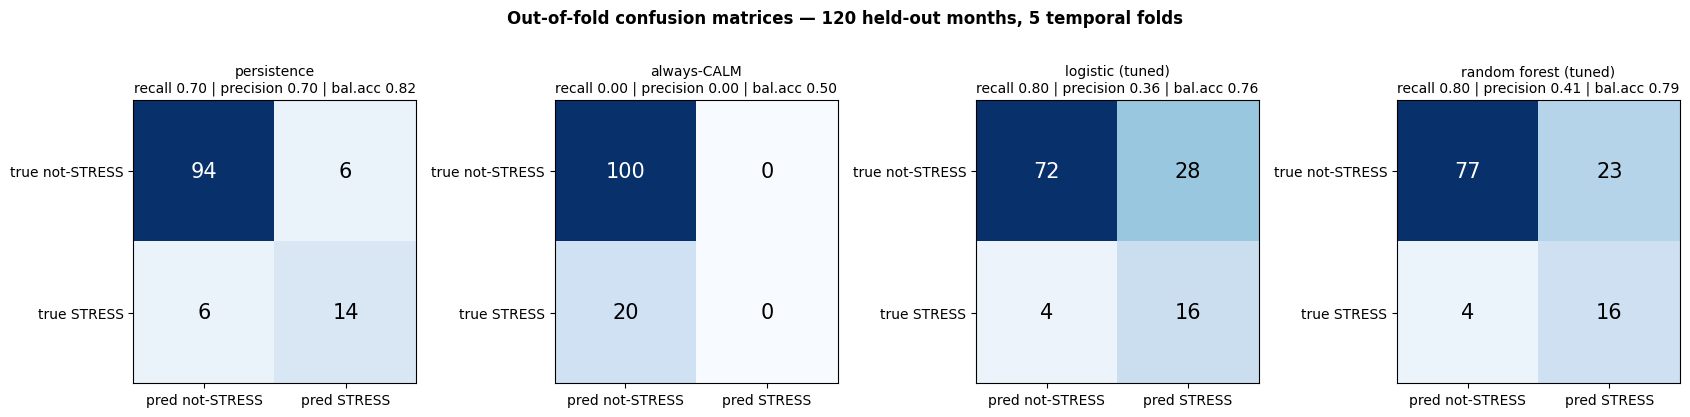

In [6]:
names = ["persistence", "always-CALM", "logistic (tuned)", "random forest (tuned)"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, name in zip(axes, names):
    cm = confusion_matrix(y_oof, preds[name], labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred not-STRESS", "pred STRESS"]); ax.set_yticklabels(["true not-STRESS", "true STRESS"])
    ax.set_title(f"{name}\nrecall {results.loc[name, 'recall_STRESS']:.2f} | precision "
                 f"{results.loc[name, 'precision_STRESS']:.2f} | bal.acc {results.loc[name, 'balanced_acc']:.2f}", fontsize=10)
fig.suptitle(f"Out-of-fold confusion matrices — {len(oof_idx)} held-out months, 5 temporal folds", fontweight="bold")
plt.tight_layout(); plt.show()

### What the models learned — an in-sample read, not an evaluation

The coefficients and importances below come from the selected configurations **refit on all 162 samples**
(what `GridSearchCV` returns after the search). They describe what each model keys on; they are not a
performance claim — the out-of-fold numbers above are. Two reading notes. With `C = 0.01` the logistic
penalty shrinks every coefficient hard toward zero, so magnitudes are small by construction and what carries
information is the **sign and the relative size** (each coefficient is the change in log-odds of STRESS per one
standard deviation of the z-scored feature). The random forest's importances are impurity-based and sum to
one; with `max_depth = 2` they say which features the stumps split on, not how.

logistic (C=0.01) — coefficients, log-odds of STRESS per 1 sd of each z-scored feature:
               coef  odds_ratio_per_sd
realized_vol  0.285              1.330
trailing_ret -0.252              0.777
avg_corr      0.107              1.113
vol_x_corr   -0.009              0.991
intercept -0.033   (class_weight='balanced' centres it near 0)

random forest (depth 2, leaf 10, 100 trees) — impurity-based importances (sum to 1):
realized_vol    0.435
trailing_ret    0.388
avg_corr        0.177


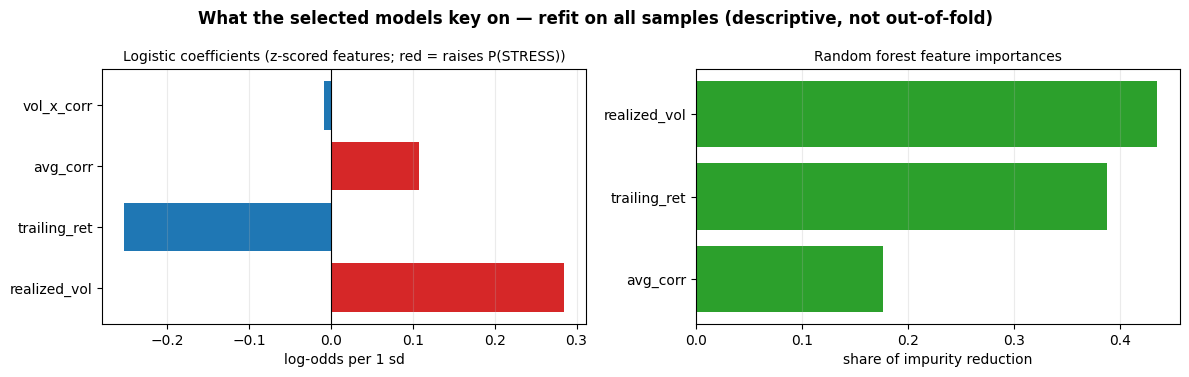

In [7]:
final_logit, final_rf = gs_logit.best_estimator_, gs_rf.best_estimator_      # refit on all samples by GridSearchCV
coef = pd.Series(final_logit.coef_[0], index=X_logit.columns)
imp = pd.Series(final_rf.feature_importances_, index=X_rf.columns)
print(f"logistic (C={final_logit.C}) — coefficients, log-odds of STRESS per 1 sd of each z-scored feature:")
print(pd.DataFrame({"coef": coef, "odds_ratio_per_sd": np.exp(coef)}).round(3).to_string())
print(f"intercept {final_logit.intercept_[0]:+.3f}   (class_weight='balanced' centres it near 0)")
print(f"\nrandom forest (depth {final_rf.max_depth}, leaf {final_rf.min_samples_leaf}, {final_rf.n_estimators} trees)"
      " — impurity-based importances (sum to 1):")
print(imp.sort_values(ascending=False).round(3).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
cols = ["#d62728" if v > 0 else "#1f77b4" for v in coef]
a1.barh(coef.index, coef.values, color=cols); a1.axvline(0, color="black", lw=0.8)
a1.set_title("Logistic coefficients (z-scored features; red = raises P(STRESS))", fontsize=10)
a1.set_xlabel("log-odds per 1 sd")
a2.barh(imp.sort_values().index, imp.sort_values().values, color="#2ca02c")
a2.set_title("Random forest feature importances", fontsize=10); a2.set_xlabel("share of impurity reduction")
for ax in (a1, a2): ax.grid(True, axis="x", alpha=0.25)
fig.suptitle("What the selected models key on — refit on all samples (descriptive, not out-of-fold)", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading.** The two models agree on the ordering: realized volatility first (logistic odds ×1.33 per standard
deviation; 44% of the forest's importance), trailing return second and in the expected direction (falling
prices raise P(STRESS); odds ×0.78 per sd of return), cross-asset correlation a distant third. The interaction
term added for the logistic model is **zero** (−0.009): the boundary did not need curving. That is consistent
with the verdict above — the K-means detector sorts its clusters by realized volatility, so a model trained on
its labels learns "volatility up, returns down → STRESS", which is the detector's own definition. Nothing in
these weights points to information that would *lead* the detector; it is the same three signals, read one
month earlier and therefore more often wrong.

### What a false negative and a false positive cost in portfolio terms

The final configuration maps CALM / NORMAL / STRESS to 100% / 90% / 60% exposure (capital freed → SHY). A
wrong regime call therefore moves roughly 30–40 percentage points of the book — we use 35 pp. The cell below
measures the monthly return of SPY and of the RP-LW base book in the held-out window, split by whether the
month was an official STRESS month — the **mean** and the **tail** (10th percentile, worst month), because the
asymmetry-of-harms argument is about bad months, not average ones — and turns the exposure gap into an
approximate cost per error. It is descriptive, not a backtest.

In [8]:
bt = pd.read_parquet(OUT_DIR / "backtest_returns.parquet")
m_ret = (1 + bt[["SPY", "RP-LW base"]]).resample("ME").prod() - 1
tm = target_month.loc[oof_idx]                              # months the held-out predictions refer to
r_oof = m_ret.reindex(tm.values) * 100                      # indexed by TARGET month (the month the return belongs to)
lab = pd.Series(np.where(y_oof.values == 1, "STRESS month", "not-STRESS month"), index=r_oof.index)
g = r_oof.groupby(lab)
by_label = pd.concat({"mean": g.mean(), "p10": g.quantile(0.10), "worst": g.min()}, axis=1)
by_label["n_months"] = lab.value_counts()
print("monthly return (%) in the held-out window, by true label — mean and tail:")
print(by_label.round(2).to_string())
print("worst month of the RP-LW base book per label:", g["RP-LW base"].idxmin().dt.strftime("%Y-%m").to_dict())

EXPO_GAP, COST_BPS = 0.35, 5.0
base = by_label.xs("RP-LW base", axis=1, level=1)
fn_mean = -EXPO_GAP * base.loc["STRESS month", "mean"]            # exposure kept in an AVERAGE stress month
fn_tail = -EXPO_GAP * base.loc["STRESS month", "p10"]             # exposure kept in a BAD stress month (10th pct)
fp_cost = EXPO_GAP * base.loc["not-STRESS month", "mean"] + 2 * EXPO_GAP * COST_BPS / 100   # forgone return + round trip
print(f"\napproximate COST per error (positive = NAV lost), RP-LW base book, {EXPO_GAP:.0%} exposure gap, {COST_BPS:.0f} bps one-way:")
print(f"  false negative, average STRESS month (book left at 90-100%) : {fn_mean:+.2f}% of NAV  (a miss gained, on average)")
print(f"  false negative, bad STRESS month (10th percentile)          : {fn_tail:+.2f}% of NAV  <- the tail the layer exists for")
print(f"  false positive, average non-STRESS month (book cut to 60%)  : {fp_cost:+.2f}% of NAV  (forgone return + costs)")

monthly return (%) in the held-out window, by true label — mean and tail:
                  mean              p10             worst            n_months
                   SPY RP-LW base   SPY RP-LW base    SPY RP-LW base         
STRESS month      0.81       0.63 -8.30      -3.55 -12.49      -5.63       20
not-STRESS month  1.36       0.64 -4.04      -2.11  -9.24      -6.38      100
worst month of the RP-LW base book per label: {'STRESS month': '2020-03', 'not-STRESS month': '2022-09'}

approximate COST per error (positive = NAV lost), RP-LW base book, 35% exposure gap, 5 bps one-way:
  false negative, average STRESS month (book left at 90-100%) : -0.22% of NAV  (a miss gained, on average)
  false negative, bad STRESS month (10th percentile)          : +1.24% of NAV  <- the tail the layer exists for
  false positive, average non-STRESS month (book cut to 60%)  : +0.26% of NAV  (forgone return + costs)


## 6 — Predicted stress probability over time (logistic, out-of-fold)

Interactive chart: hover shows the month being predicted, the probability, the date the prediction was
issued and whether the month turned out to be official STRESS (shaded). A static copy of the same figure is
embedded below it so the chart also renders where JavaScript is stripped (github.com); the interactive HTML
is saved to `outputs/supervised_pstress_logistic.html`.

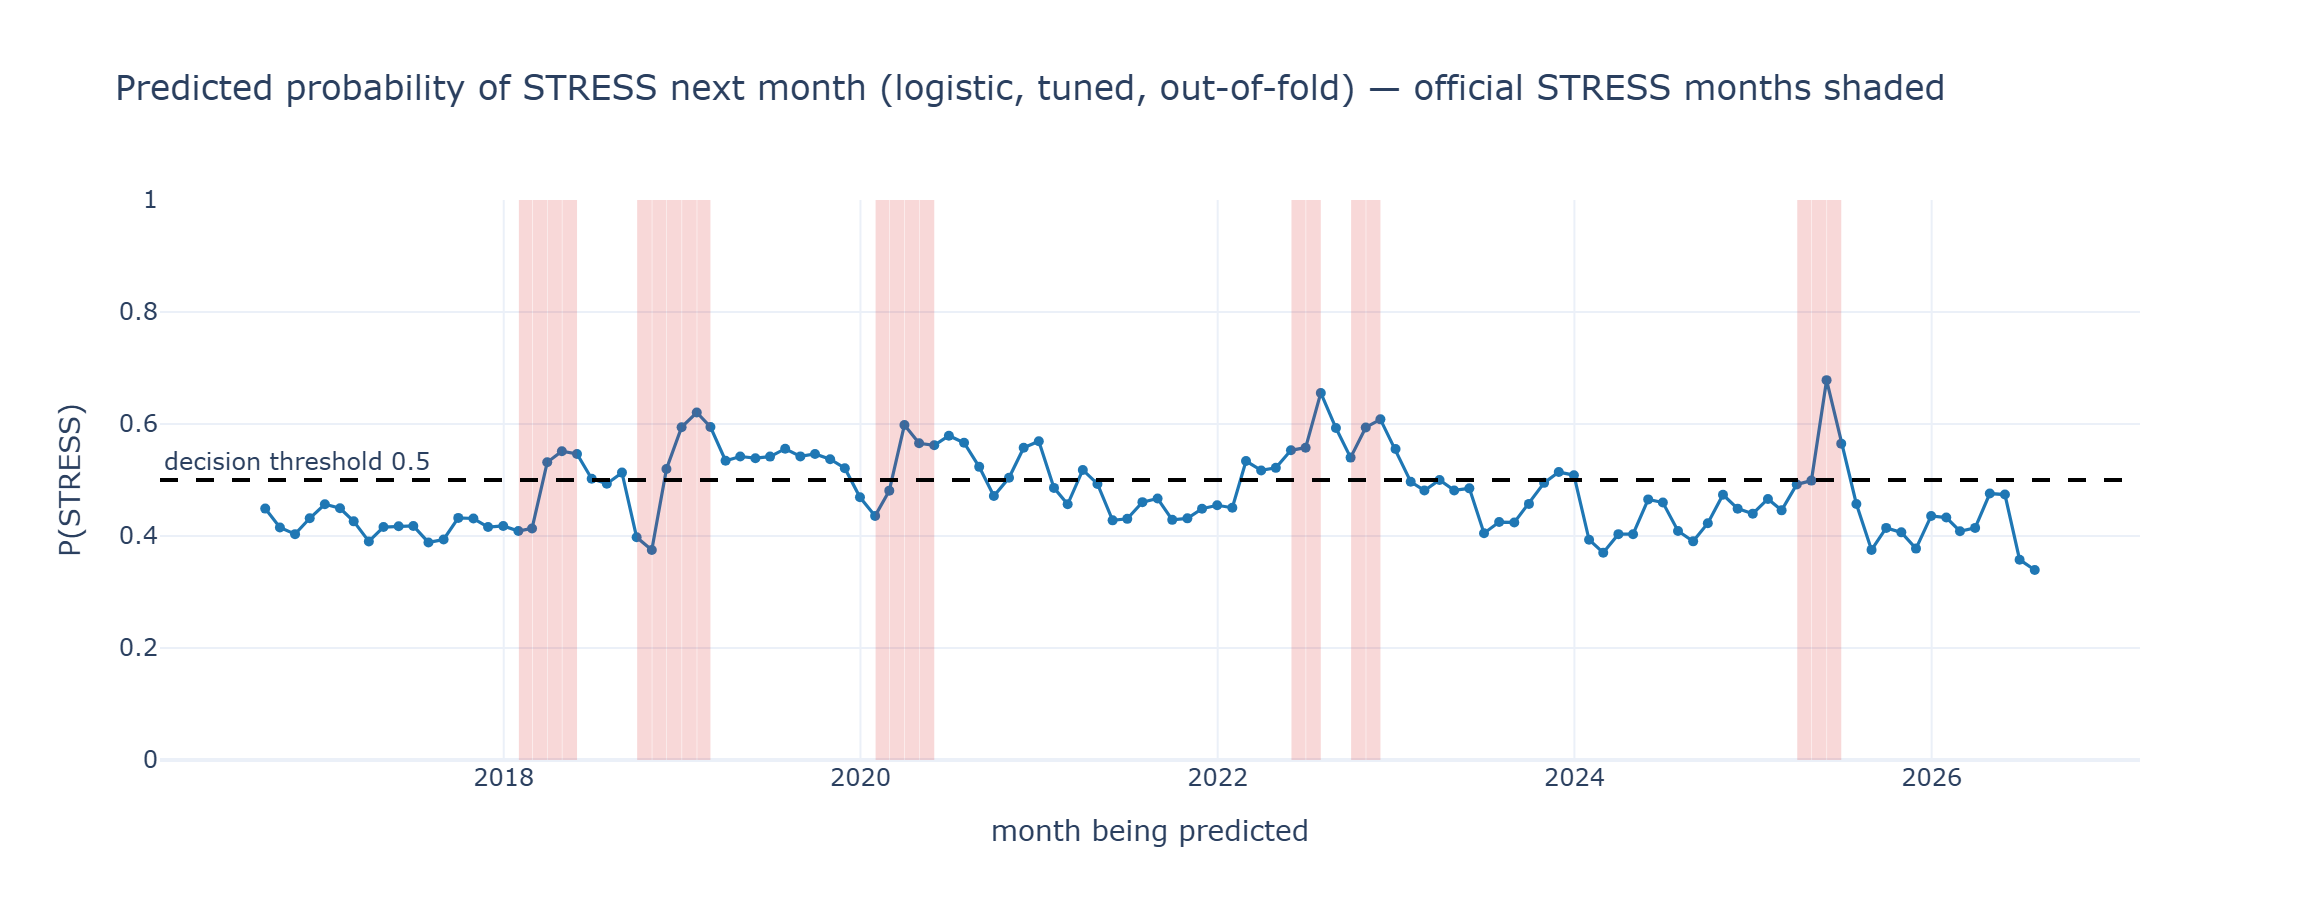

In [9]:
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image, display
pio.renderers.default = "plotly_mimetype+notebook_connected"   # figure JSON stays in the .ipynb; plotly.js from CDN

plot_df = pd.DataFrame({"issued_at": oof_idx, "p_stress": p_logit.values, "true": y_oof.values},
                       index=pd.DatetimeIndex(tm.values, name="target_month"))
fig = go.Figure()
for T in official.index[official == "STRESS"]:                 # shade official STRESS months (calendar month of T)
    if T >= plot_df.index.min():
        fig.add_vrect(x0=T - pd.offsets.MonthBegin(1), x1=T, fillcolor="#d62728", opacity=0.18, line_width=0)
fig.add_trace(go.Scatter(
    x=plot_df.index, y=plot_df["p_stress"], mode="lines+markers", name="logistic P(STRESS next month), out-of-fold",
    line=dict(color="#1f77b4", width=1.6), marker=dict(size=5),
    customdata=np.stack([plot_df["issued_at"].dt.strftime("%Y-%m-%d"),
                         np.where(plot_df["true"] == 1, "yes", "no")], axis=1),
    hovertemplate="month %{x|%Y-%m}<br>P(STRESS) = %{y:.2f}<br>issued at %{customdata[0]}"
                  "<br>official STRESS: %{customdata[1]}<extra></extra>"))
fig.add_hline(y=0.5, line_dash="dash", line_color="black", annotation_text="decision threshold 0.5",
              annotation_position="top left")
fig.update_layout(title="Predicted probability of STRESS next month (logistic, tuned, out-of-fold) — official STRESS months shaded",
                  xaxis_title="month being predicted", yaxis_title="P(STRESS)", yaxis_range=[0, 1],
                  template="plotly_white", height=460, width=1150, legend=dict(orientation="h", y=1.08, x=0))
fig.show()
fig.write_html(OUT_DIR / "supervised_pstress_logistic.html", include_plotlyjs="cdn")
try:   # static PNG twin for renderers that strip JavaScript (github.com); needs kaleido + a local Chrome
    display(Image(fig.to_image(format="png", scale=2)))
except Exception as e:
    print(f"static PNG skipped ({type(e).__name__}); the interactive HTML is in outputs/")

In [10]:
oof = pd.DataFrame({"issued_at": oof_idx, "target_month": tm.values, "fold": fold_id.values,
                    "y_true": y_oof.values, "persistence": preds["persistence"].values,
                    "p_logit": p_logit.values, "pred_logit": preds["logistic (tuned)"].values,
                    "p_rf": p_rf.values, "pred_rf": preds["random forest (tuned)"].values})
oof.to_parquet(OUT_DIR / "supervised_oof.parquet", index=False)
results.rename_axis("model").to_csv(OUT_DIR / "supervised_metrics.csv")
print("saved outputs/supervised_oof.parquet, outputs/supervised_metrics.csv, outputs/supervised_pstress_logistic.html")

saved outputs/supervised_oof.parquet, outputs/supervised_metrics.csv, outputs/supervised_pstress_logistic.html


## 7 — Verdict: prediction does not beat description

**Neither tuned model beats persistence out-of-fold under the rule declared in section 4.** On the 120 held-out
months (20 official STRESS targets):

| predictor | recall STRESS | precision STRESS | balanced acc. | TP / FP / FN |
|---|---|---|---|---|
| persistence (regime at T carried to T+1) | 0.70 | 0.70 | **0.82** | 14 / 6 / 6 |
| always-CALM | 0.00 | — | 0.50 | 0 / 0 / 20 |
| logistic, tuned (C = 0.01) | **0.80** | 0.36 | 0.76 | 16 / 28 / 4 |
| random forest, tuned (depth 2, leaf 10, 100 trees) | **0.80** | 0.41 | 0.79 | 16 / 23 / 4 |

Both models raise recall by two months (16 vs 14 of 20) and pay for it with 22 and 17 **extra** false alarms;
balanced accuracy falls below persistence's for both, so condition (ii) of the decision rule fails. Under
rule 6 this is the expected and acceptable outcome, recorded like every other negative finding in this project.

**Why persistence is so hard to beat here.** Its six misses are *exactly* the six episode onsets in the window
(2018-02, 2018-10, 2020-02, 2022-06, 2022-10, 2025-04) and its six false alarms are *exactly* the six exit
months. Persistence is right about every continuation month and wrong about every turning point — so the only
way to beat it is to call onsets early without inventing them. The models called **two of six** onsets
(2022-06 and 2022-10, both inside the 2022 bear, when volatility and correlation were already elevated) and
missed the four sudden ones; for February 2020 the logistic probability was 0.48 — the crash began on the 20th
and only one week of it sits inside the 8-week volatility window at month-end. The false alarms cluster in
NORMAL months around episodes (2019, the second half of 2020, early 2022): what the models learned is
"elevated volatility and correlation → STRESS", which is the detector's own definition at a lower threshold.
In effect they **re-describe the present** rather than predict a turn.

**The grid search had no prize to find.** All four logistic and all twelve random-forest configurations sit
within two points of CV recall (0.817–0.839); ties were broken toward the simplest settings. Hyperparameters
are not what limits this task — the information content of three backward-looking features at a one-month
horizon is.

**Cost of an error, in portfolio terms.** In this window the average official STRESS month was *not* a losing
month for the diversified book (+0.6% vs +0.6% in other months): by the time stress is official and one more
month has passed, the average month is flat. So the mean cost of a false negative is about zero and that of a
false positive about −0.3% of NAV (forgone return plus costs). The case for calling stress lives in the
**tail**: the 10th-percentile STRESS month costs the base book −3.6% (vs −2.1% in other months), so a missed
bad month costs roughly 1.2% of NAV at a 35-pp exposure gap, four times a false alarm. That asymmetry justifies
recall as the primary metric — but it also shows why recall alone is not enough: 23–28 false alarms at −0.3%
each outweigh the two extra onsets caught. One more honest number: the book's worst held-out month (2022-09,
−6.4%) was *not* an official STRESS month — the label is itself a lagging description, and any model trained
on it inherits that lag.

## 8 — Frozen configuration unchanged

No supervised model is promoted into the production pipeline. The final configuration stays exactly as frozen
in Step 10: V-AB (Risk-Parity on Ledoit-Wolf covariance, IEF capped at 25%, momentum tilt ±20%, K-means regime
detector on a 5-year rolling window with asymmetric hysteresis, soft exposure map 100/90/60 with 1-month
stress exit, freed capital to SHY). This notebook adds three things to the record, none of them a change:

1. The rubric's modeling items — two classifiers, temporal cross-validation, grid search — exist and were run
   honestly, with grids, metrics and the decision rule fixed before any result was seen.
2. The project's **label-lag rule (rule 5)** has now been exercised in code (`gap=1` in `TimeSeriesSplit`),
   not only declared.
3. A negative finding with a mechanism: at a one-month horizon, on the detector's own features, prediction
   collapses to description. If this question is reopened, the lever is **features that lead the detector**
   (credit spreads, the VIX term structure already in `data/`), not a better classifier on the same three —
   flagged for future work, not pursued, under rule 6 and the submission freeze.

Outputs written: `outputs/supervised_oof.parquet` (out-of-fold probabilities and predictions, with the issue
date and the target month), `outputs/supervised_metrics.csv`, `outputs/supervised_pstress_logistic.html`.